# Makale Yeniden Üretimi · Bölüm 7: Lojistik Regresyon

**Ahmet Batuhan Kaya · 20269348005**

**Makale:** Liu, J., Zhong, C., Li, B., Seltzer, M. ve Rudin, C. (2022). *FasterRisk: Fast and Accurate Interpretable Risk Scores.* Advances in Neural Information Processing Systems 35 (NeurIPS 2022), 17760–17773.

**Bölümle bağlantısı:** Molnar'ın 7. bölümünde lojistik regresyonun katsayıları log-odds ölçeğinde yorumlanıyor; yorum için hesap makinesi gerekiyor. **Risk puanı**, lojistik regresyonun en sade hâli: az sayıda öznitelik ve küçük tam sayı katsayılar. Hekim ya da kredi uzmanı puanları kâğıt üzerinde toplayıp riski tablodan okuyabilir. FasterRisk bu kartları veriden hızlı ve doğru öğrenen yeni bir algoritma.

**Hocanın seçeneklerinden:** Seçenek 3, *Geliştirme/Modifikasyon*. Temel algoritmanın (lojistik regresyon) üzerine yorumlanabilirlik ve hız katan yeni bir varyant.

**Bu defterde:**

1. Makalenin örnek puan kartını (mammo verisi) yeniden üretiyoruz.
2. Makalenin dört veri setinde FasterRisk'i, lasso + yuvarlama yöntemleriyle 5 katlı çapraz doğrulamada kıyaslıyoruz.
3. **Uzantı:** 7. bölüm uygulamasındaki German Credit verisinden bir kredi riski puan kartı kuruyoruz.

**Çalıştırma:** `pip install numpy pandas scikit-learn matplotlib requests pillow joblib`. FasterRisk'in kendisi bu klasördeki `fasterrisk/` alt klasöründen yüklenir; PyPI paketi güncel Python'da kurulmadığı için kaynak kodunu iki satırlık bir yamayla klasöre koyduk (ayrıntı: `fasterrisk/README.md`). Büyük kıyaslama iki çekirdekte ~11 dakika sürdüğü için hazır sonuçlar `sonuclar/` klasöründen okunur; baştan üretmek için `YENIDEN_CALISTIR = True` yapın.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score

from fasterrisk.fasterrisk import RiskScoreOptimizer, RiskScoreClassifier
import puan, kredi

YENIDEN_CALISTIR = False   # True: büyük kıyaslamayı (~11 dk) ve kredi deneyini (~2 dk) baştan çalıştırır

## 1. Risk puanı nedir? Makalenin örneği

Makalenin Şekil 1'i, meme lezyonunun kötü huylu olma riskini tahmin eden 5 öznitelikli bir puan kartı. Aynı veriyle (mammo, 961 hasta) kartı yeniden üretelim. Her öznitelik 0/1; puanlar −5 ile 5 arasında tam sayı. Risk:

$$P(y=1) = \frac{1}{1 + e^{-(\text{kesişim} + \text{toplam puan}) / \text{çarpan}}}$$

Çarpan, puanları tam sayı tutarken olasılık ölçeğini ayarlayan tek bir sayı.

In [2]:
d = pd.read_csv("veri/mammo_data.csv")
y = d.iloc[:, 0].to_numpy() * 2 - 1          # FasterRisk etiketleri -1 / +1 bekler
X = d.iloc[:, 1:].to_numpy(float)

opt = RiskScoreOptimizer(X=X, y=y, k=5, parent_size=10)
opt.optimize()
carpanlar, kesisimler, katsayilar = opt.get_models()
kart = RiskScoreClassifier(carpanlar[0], kesisimler[0], katsayilar[0])
kart.reset_featureNames(list(d.columns[1:]))
print("Eğitim AUC:", round(roc_auc_score(y, kart.predict_prob(X)), 3), "· makaledeki kart: 0,854")
kart.print_model_card()

Eğitim AUC: 0.855 · makaledeki kart: 0,854
The Risk Score is:
1.       IrregularShape      2 point(s) |   ...
2.  CircumscribedMargin     -3 point(s) | + ...
3.     SpiculatedMargin      1 point(s) | + ...
4.           Age_geq_30      3 point(s) | + ...
5.           Age_geq_60      2 point(s) | + ...
                                  SCORE | =    
SCORE |  -3.0  |  -2.0  |  -1.0  |   0.0  |   1.0  |   2.0  |
RISK  |   1.9% |   3.3% |   5.7% |   9.6% |  15.6% |  24.5% |
SCORE |   3.0  |   4.0  |   5.0  |   6.0  |   7.0  |   8.0  |
RISK  |  36.3% |  50.0% |  63.7% |  75.5% |  84.4% |  90.4% |


Makaledeki kartla aynı öznitelikler öne çıkıyor: düzensiz şekil ve dikenli kenar riski artırıyor, düzgün sınırlı kenar riski azaltıyor, yaş arttıkça risk artıyor. Puanlar makaledekinden biraz farklı olabilir; makale kartı 5 katın birinde eğitti, biz tüm veride eğittik. AUC değerleri aynı düzeyde.

## 2. Kıyaslama düzeni

| Öğe | Değer |
|---|---|
| Veriler | mammo, mushroom, adult, bank (makaledeki 6 veri setinden herkese açık 4'ü; ikili öznitelikler RiskSLIM deposundan) |
| Kart boyutu | k = 3, 5, 7, 10 |
| Puan aralığı | −5 … 5 tam sayı |
| Değerlendirme | 5 katlı çapraz doğrulama, test AUC |

| Yöntem | Ne yapar |
|---|---|
| **FasterRisk** | Seyrek ışın araması (her adımda 10 aday) + aynı kalitede modellerden çeşitli bir havuz + yıldız ışını araması ve sıralı yuvarlama |
| **Lasso + ölçekle-yuvarla** | L1 lojistik regresyon k öznitelik seçer, katsayılar en büyüğü 5 olacak biçimde ölçeklenip yuvarlanır (makaledeki "pooled" yuvarlama yöntemlerine en yakın) |
| **Lasso + yuvarlama** | Aynı katsayılar doğrudan en yakın tam sayıya yuvarlanır |
| **Lasso + EKK (sürekli)** | Yuvarlama yok: lasso'nun seçtiği k öznitelikle sürekli lojistik regresyon |
| **Tam lojistik regresyon** | Bütün öznitelikler, sürekli katsayılar (üst referans) |

**Makaleden farkımız:** Makalenin ana rakibi RiskSLIM, ticari CPLEX çözücüsü gerektirdiği için çalıştırılamadı. Onun yerine yuvarlama tabanlı rakipleri kullandık. COMPAS ve FICO verilerini almadık.

In [3]:
if YENIDEN_CALISTIR:
    import subprocess, sys
    subprocess.run([sys.executable, "calistir.py"], check=True)
sonuc = pd.read_csv("sonuclar/kiyaslama.csv")
print(len(sonuc), "satır")

340 satır


## 3. Sonuçlar ve makalenin iddiaları

### İddia 1: "FasterRisk, aynı model boyutunda rakiplerinden daha yüksek AUC verir."

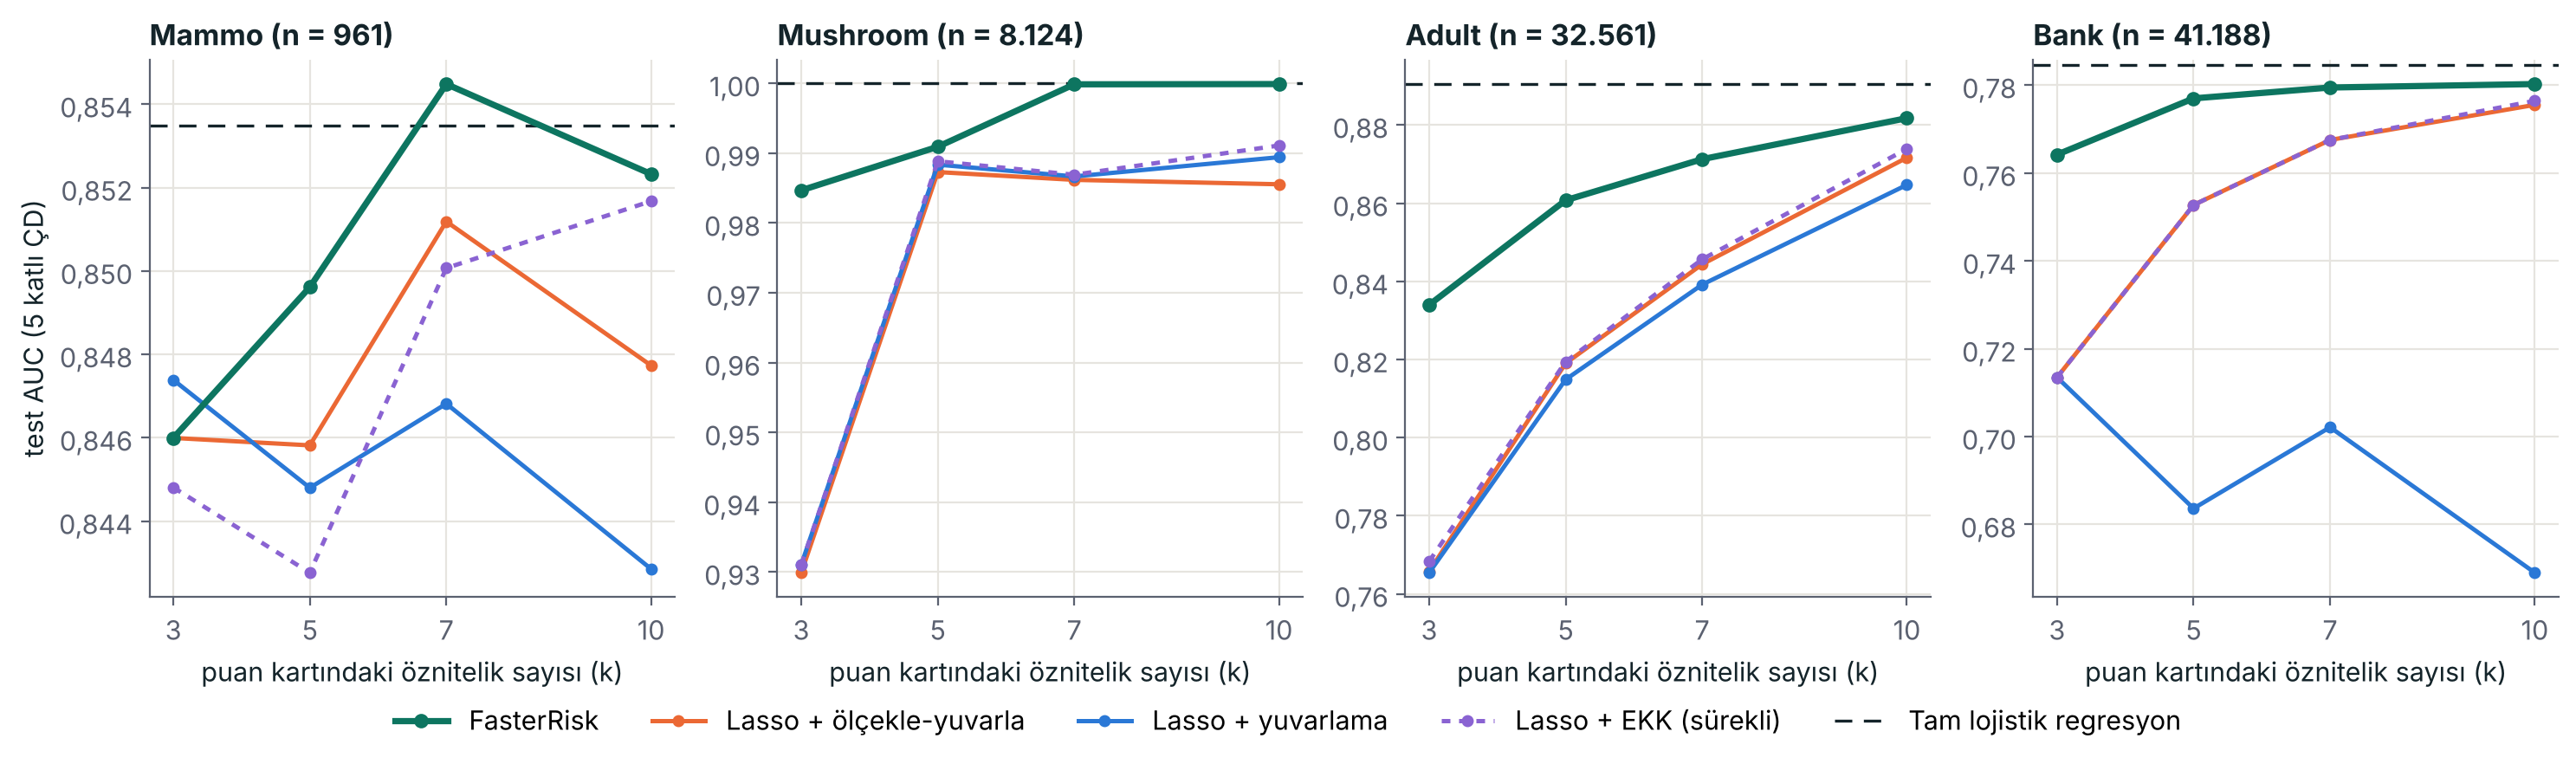

yontem       FasterRisk  Lasso + EKK (sürekli)  Lasso + yuvarlama  \
veri     k                                                          
adult    3        0.834                  0.768              0.765   
         5        0.861                  0.819              0.815   
         7        0.871                  0.846              0.839   
         10       0.882                  0.874              0.865   
bank     3        0.764                  0.713              0.713   
         5        0.777                  0.753              0.684   
         7        0.779                  0.768              0.702   
         10       0.780                  0.776              0.669   
mammo    3        0.846                  0.845              0.847   
         5        0.850                  0.843              0.845   
         7        0.854                  0.850              0.847   
         10       0.852                  0.852              0.843   
mushroom 3        0.985                  0.931              0.931   
         5        0.991                  0.989              0.988   
         7        1.000                  0.987              0.987   
         10       1.000                  0.991              0.989   

yontem       Lasso + ölçekle-yuvarla  FasterRisk farkı (ölçekle-yuvarla)  
veri     k                                                                
adult    3                     0.766                               0.068  
         5                     0.819                               0.042  
         7                     0.844                               0.027  
         10                    0.872                               0.010  
bank     3                     0.713                               0.051  
         5                     0.753                               0.024  
         7                     0.768                               0.011  
         10                    0.776                               0.004  
mammo    3                     0.846                               0.000  
         5                     0.846                               0.004  
         7                     0.851                               0.003  
         10                    0.848                               0.004  
mushroom 3                     0.930                               0.055  
         5                     0.987                               0.004  
         7                     0.986                               0.014  
         10                    0.986                               0.014

In [4]:
display(Image("sekiller/sekil1_kiyaslama.png", width=1000))
t = sonuc[sonuc.yontem != "Tam lojistik regresyon"].pivot_table(index=["veri", "k"], columns="yontem", values="auc_test").round(3)
t["FasterRisk farkı (ölçekle-yuvarla)"] = (t["FasterRisk"] - t["Lasso + ölçekle-yuvarla"]).round(3)
t

16 karşılaştırmanın 14'ünde FasterRisk açıkça birinci. Kalan ikisi mammo'da: k = 10'da eşit, k = 3'te 0,001 geride. Mammo küçük ve kolay bir veri; oradaki farklar gürültü düzeyinde. Fark en çok küçük kartlarda büyük: adult'ta k = 3 için 0,834'e karşı 0,766. Dikkat çekici bir nokta: FasterRisk, **yuvarlanmamış** lasso modelini bile geçiyor. Yani üstünlük yalnızca iyi yuvarlamadan değil, ışın aramasının daha iyi öznitelik seçmesinden de geliyor.

Doğrudan yuvarlama (mavi) ise tehlikeli: bank verisinde k arttıkça AUC düşüyor, çünkü küçük katsayılar sıfıra yuvarlanıp kayboluyor.

### İddia 2: "FasterRisk dakikalar içinde biter."

In [5]:
sonuc[sonuc.yontem == "FasterRisk"].pivot_table(index="veri", columns="k", values="sure").round(1)

k,3,5,7,10
veri,,,,
adult,1.9,9.3,15.6,32.5
bank,7.3,18.7,37.3,79.4
mammo,0.2,0.7,1.2,1.7
mushroom,0.8,2.5,8.7,13.7


Süreler saniye cinsinden, bir katın ortalaması. En büyük veri setinde (bank, 33 bin eğitim gözlemi) bile 10 öznitelikli kart 80 saniyenin altında. Makale RiskSLIM'in aynı boyutlarda 15 dakikalık süre sınırına takıldığını raporluyor; biz RiskSLIM'i çalıştıramadığımız için bu karşılaştırmayı tekrar etmedik.

### İddia 3: "Tek bir model değil, aynı kalitede birçok model üretir."

FasterRisk'in havuzu, kaybı en iyiye yakın olan farklı kartları birlikte verir. Kullanıcı aralarından alan bilgisine en uygun olanı seçebilir.

In [6]:
for i in range(3):
    c = RiskScoreClassifier(carpanlar[i], kesisimler[i], katsayilar[i])
    oz = [(d.columns[1:][j], int(katsayilar[i][j])) for j in np.flatnonzero(katsayilar[i])]
    print(f"Kart {i+1}: AUC {roc_auc_score(y, c.predict_prob(X)):.3f} ·", oz)

Kart 1: AUC 0.855 · [('IrregularShape', 2), ('CircumscribedMargin', -3), ('SpiculatedMargin', 1), ('Age_geq_30', 3), ('Age_geq_60', 2)]
Kart 2: AUC 0.855 · [('IrregularShape', 2), ('CircumscribedMargin', -3), ('SpiculatedMargin', 1), ('Age_lt_30', -3), ('Age_geq_60', 2)]
Kart 3: AUC 0.854 · [('OvalShape', -1), ('IrregularShape', 2), ('CircumscribedMargin', -3), ('SpiculatedMargin', 1), ('Age_geq_60', 2)]


## 4. Uzantı: German Credit için kredi riski puan kartı

7. bölüm uygulamasında German Credit verisinde lojistik regresyon kurmuştuk. Şimdi aynı veriden bir puan kartı öğreniyoruz. Sürekli öznitelikleri eşiklerle ikiliye çevirdik (ör. vade ≥ 24 ay). Cinsiyet, medeni durum ve yabancı işçi bilgisini ayrımcılık riski nedeniyle modele almadık. Sonuç: 25 ikili öznitelik.

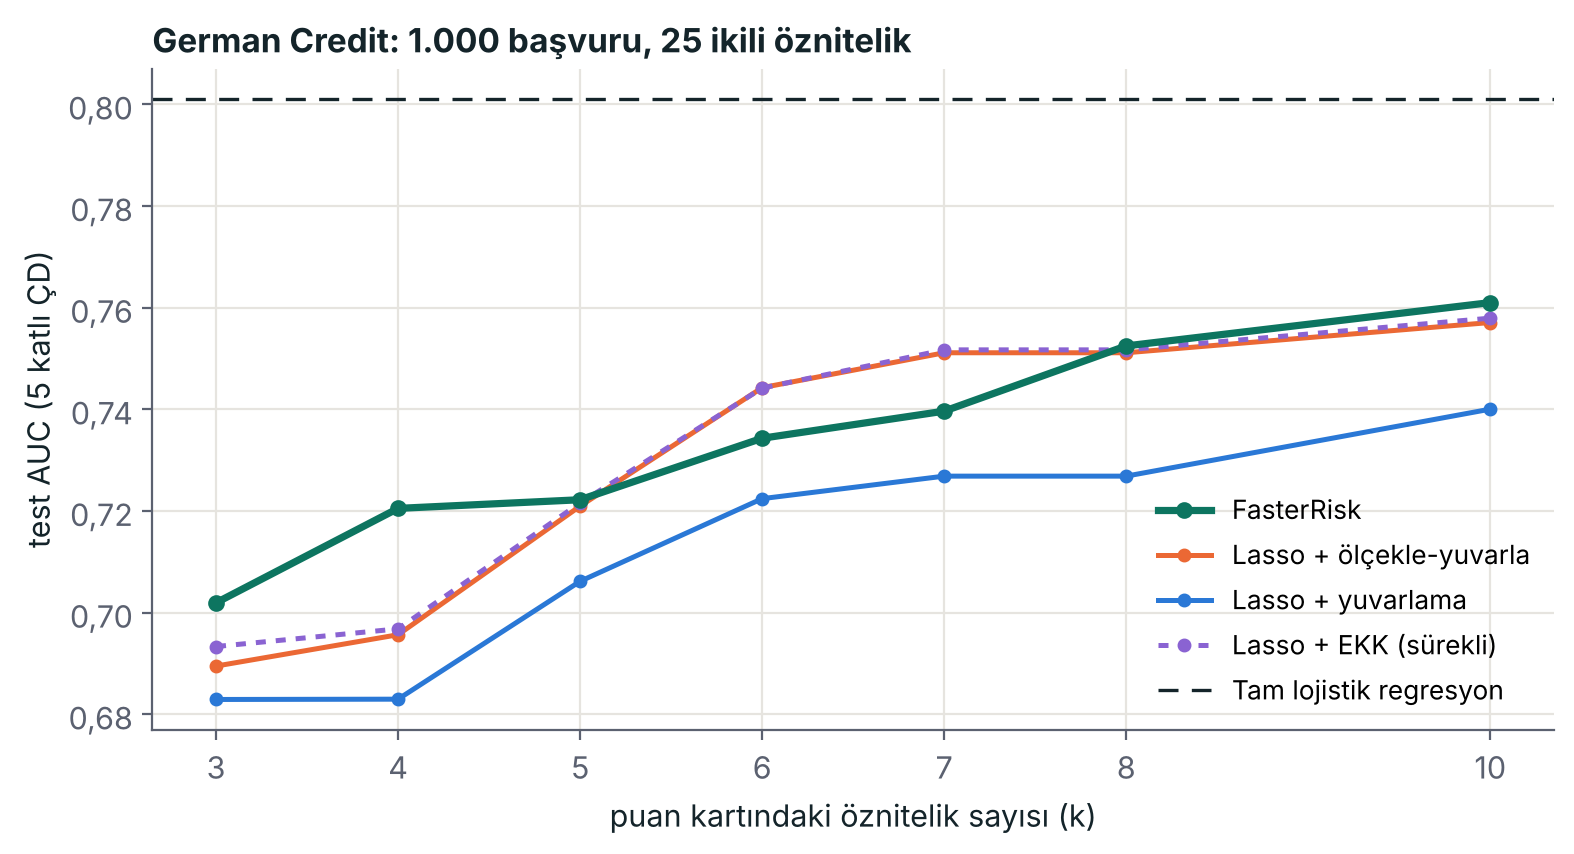

yontem,FasterRisk,Lasso + EKK (sürekli),Lasso + yuvarlama,Lasso + ölçekle-yuvarla,Tam lojistik regresyon
k,,,,,
3,0.702,0.693,0.683,0.690,NaN
4,0.721,0.697,0.683,0.696,NaN
5,0.722,0.722,0.706,0.721,NaN
6,0.734,0.744,0.722,0.744,NaN
7,0.740,0.752,0.727,0.751,NaN
8,0.753,0.752,0.727,0.751,NaN
10,0.761,0.758,0.740,0.757,NaN
25,NaN,NaN,NaN,NaN,0.801


In [7]:
if YENIDEN_CALISTIR:
    subprocess.run([sys.executable, "calistir_kredi.py"], check=True)
kcd = pd.read_csv("sonuclar/kredi_cd.csv")
display(Image("sekiller/sekil2_kredi.png", width=700))
kcd.pivot_table(index="k", columns="yontem", values="auc_test").round(3)

Bu küçük ve gürültülü veride tablo farklı: FasterRisk k = 3, 4, 8 ve 10'da önde, k = 6 ve 7'de sürekli lasso modelinin ~0,01 gerisinde. Eğitim AUC'sinde ise her k için önde. 1.000 başvuruluk veride eğitimdeki üstünlük teste her zaman yansımıyor.

Yorumlanabilirliğin bedeli de görünüyor: 25 öznitelikli tam lojistik regresyon 0,801; 10 puanlık kart 0,761.

Şimdi tüm veriyle 5 öznitelikli kartı kuralım:

In [8]:
Xk, yk = kredi.kredi_verisi()
havuz, sure = puan.fasterrisk_kur(Xk.to_numpy(), yk, k=5)
satirlar, tablo = kredi.kart_tablosu(havuz[0], list(Xk.columns))
print(f"{sure:.1f} saniyede kuruldu.\n")
for ad, p in satirlar:
    print(f"{ad:<32} {p:+d} puan")
print("\nPuan → temerrüt riski")
print(tablo.assign(risk=(100 * tablo.risk).round(1).astype(str) + " %").to_string(index=False))

0.7 saniyede kuruldu.

Hesap bakiyesi eksi              +4 puan
Hesap bakiyesi 0-200 DM          +3 puan
Tutar ≥ 4.000 DM                 +2 puan
Geçmiş: kritik hesap             -2 puan
Amaç: ikinci el araba            -3 puan

Puan → temerrüt riski
 puan   risk
   -5  1.9 %
   -4  2.9 %
   -3  4.4 %
   -2  6.7 %
   -1 10.0 %
    0 14.7 %
    1 21.1 %
    2 29.4 %
    3 39.2 %
    4 50.0 %
    5 60.8 %
    6 70.6 %
    7 78.9 %
    8 85.3 %
    9 90.0 %


Kart beklenen şeyleri söylüyor: eksi bakiyeli hesap, yüksek tutar riski artırıyor. Ama bir satır sezgiye aykırı: **"Geçmiş: kritik hesap" riski azaltıyor**. 7. bölüm uygulamasında lojistik regresyonda da aynı işareti görmüştük. Bu, verideki seçilim yanlılığına ya da bilinen kodlama hatalarına işaret ediyor (Grömping, 2019). Puan kartı bu sorunu tek satırda, herkesin görebileceği biçimde ortaya koyuyor; yorumlanabilir modelin asıl faydası bu.

## 5. Özet

| Makalenin iddiası | Bizim sonucumuz |
|---|---|
| Aynı boyutta en yüksek AUC | ✔ 16 karşılaştırmanın 14'ünde birinci; mammo'daki 2'sinde fark ≤ 0,001 |
| Dakikalar içinde biter | ✔ En büyük veride 10 öznitelikli kart < 80 sn |
| Aynı kalitede birden çok model | ✔ Havuzdan birbirine yakın AUC'lu farklı kartlar |
| RiskSLIM'den iyi | Tekrar edilemedi (CPLEX gerekli) |
| **Uzantı** | Küçük kredi verisinde üstünlük testte kısmen kayboluyor; kart, verideki tuhaf bir ilişkiyi görünür kılıyor |

**Sınırlılıklar:** RiskSLIM, COMPAS ve FICO yok. Rakip olarak makaledeki "pooled" yöntemlerin sadeleştirilmiş hâlini kullandık. Kartlar tüm veride eğitildi; sunumdaki AUC'ler çapraz doğrulamadan geliyor.